# Overflow metabolism in *E. coli*: a small flux balance analysis project

When *E. coli* grows fast, it secretes acetate even if oxygen is available. This looks wasteful, because respiration gives much more ATP per glucose than fermentation does.

In this notebook I use the *E. coli* core metabolic model and flux balance analysis (FBA) to look at this in three parts:

- **Part A:** basic FBA. Growth at different glucose levels, growth without oxygen, and essential genes.
- **Part B:** basic FBA never predicts acetate secretion when oxygen is available.
- **Part C:** after adding one extra rule (a limited protein budget), the model does predict acetate overflow.

Part C is a simplified reproduction of the idea in Basan et al. (2015). This is a learning project and not a new result.

## Setup: load the model

The model is the *E. coli* core model that comes with COBRApy. It contains the central metabolism: glycolysis, the pentose phosphate pathway, the TCA cycle, respiration and fermentation.

In [1]:
from cobra.io import load_model
import matplotlib.pyplot as plt
import numpy as np

model = load_model("textbook")   # the E. coli core model
print(len(model.reactions), "reactions")
print(len(model.metabolites), "metabolites")
print(len(model.genes), "genes")

95 reactions
72 metabolites
137 genes


## Part A: basic FBA

### A1. First simulation

FBA finds the flux through every reaction that gives the fastest growth, with two conditions: no metabolite is allowed to accumulate, and each reaction has a maximum flux. The most important limit is the glucose uptake, which is 10 mmol/gDW/h by default.

In [2]:
solution = model.optimize()
print("Growth rate:", solution.objective_value)
model.summary()

Growth rate: 0.8739215069684279


Metabolite,Reaction,Flux,C-Number,C-Flux
glc__D_e,EX_glc__D_e,10,6,100.00%
nh4_e,EX_nh4_e,4.765,0,0.00%
o2_e,EX_o2_e,21.8,0,0.00%
pi_e,EX_pi_e,3.215,0,0.00%
Metabolite,Reaction,Flux,C-Number,C-Flux
co2_e,EX_co2_e,-22.81,1,100.00%
h2o_e,EX_h2o_e,-29.18,0,0.00%
h_e,EX_h_e,-17.53,0,0.00%


The growth rate is 0.874 per hour, which is a doubling time of about 48 minutes. The cell uses all the glucose it is allowed to take. It releases only CO2, water and protons, and no acetate. So with oxygen the model burns glucose completely by respiration.

### A2. Growth at different glucose levels

Here I change the glucose uptake limit and record the growth rate each time.

glucose: 1  growth: 0.04838497229681491
glucose: 2  growth: 0.14060353596759154
glucose: 5  growth: 0.41559777509290635
glucose: 10  growth: 0.8739215069684305
glucose: 15  growth: 1.332245238843955
glucose: 20  growth: 1.7905689707194807


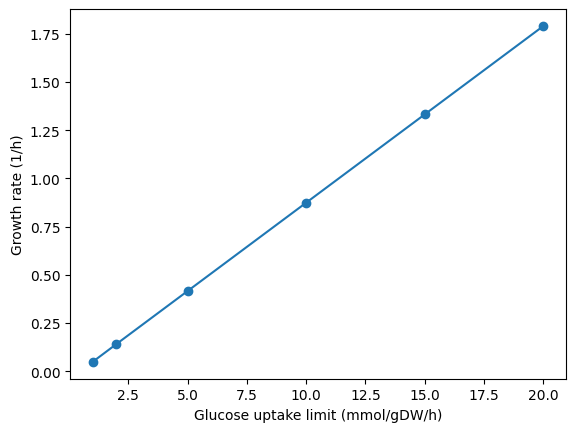

In [3]:
glucose_limits = [1, 2, 5, 10, 15, 20]
growth_rates = []

for g in glucose_limits:
    # uptake is written as a negative number, so -g means "can take up to g"
    model.reactions.EX_glc__D_e.lower_bound = -g
    solution = model.optimize()
    growth_rates.append(solution.objective_value)
    print("glucose:", g, " growth:", solution.objective_value)

plt.plot(glucose_limits, growth_rates, "o-")
plt.xlabel("Glucose uptake limit (mmol/gDW/h)")
plt.ylabel("Growth rate (1/h)")
plt.show()

# put glucose back to the original value
model.reactions.EX_glc__D_e.lower_bound = -10

Growth increases in a straight line with glucose. The growth rate at 5 glucose (0.416) is a little less than half of the growth rate at 10 glucose (0.874). The reason is that the cell needs some ATP only to stay alive (maintenance), even when it does not grow. The line reaches zero growth at about 0.5 glucose, and only the glucose above this amount is used for growth.

The line never bends. In this model the growth rate keeps increasing as long as more glucose is given, which is not realistic. I come back to this in Part C.

### A3. Growth without oxygen

In [4]:
# turn oxygen off: the cell is not allowed to take up any
model.reactions.EX_o2_e.lower_bound = 0

solution = model.optimize()
print("Growth rate without oxygen:", solution.objective_value)
model.summary()

Growth rate without oxygen: 0.21166294973531047


Metabolite,Reaction,Flux,C-Number,C-Flux
co2_e,EX_co2_e,0.3782,1,0.63%
glc__D_e,EX_glc__D_e,10,6,99.37%
h2o_e,EX_h2o_e,7.116,0,0.00%
nh4_e,EX_nh4_e,1.154,0,0.00%
pi_e,EX_pi_e,0.7786,0,0.00%
Metabolite,Reaction,Flux,C-Number,C-Flux
ac_e,EX_ac_e,-8.504,2,33.11%
etoh_e,EX_etoh_e,-8.279,2,32.23%
for_e,EX_for_e,-17.8,1,34.66%
h_e,EX_h_e,-30.55,0,0.00%


Without oxygen the growth rate drops to 0.212, about a quarter of the value with oxygen, because fermentation gives much less ATP per glucose. The cell now secretes acetate, ethanol and formate (mixed-acid fermentation).

This also shows that the model is able to produce acetate. With oxygen it does not, because respiration is the better plan.

In [5]:
# turn oxygen back on and check that growth is back to the first value
model.reactions.EX_o2_e.lower_bound = -1000
print("Growth rate with oxygen:", model.optimize().objective_value)

Growth rate with oxygen: 0.8739215069684334


### A4. Essential genes

Here I remove one gene at a time and check if the model can still grow. If it cannot, the gene is essential in this condition (glucose, with oxygen).

In [6]:
essential_genes = []

for gene in model.genes:
    with model:   # anything changed inside this block is undone afterwards
        gene.knock_out()
        solution = model.optimize()
        # no valid plan, or almost no growth, means the gene is essential
        if solution.status != "optimal" or solution.objective_value < 0.01:
            essential_genes.append(gene)

print("Number of essential genes:", len(essential_genes))
for gene in essential_genes:
    print(gene.id, gene.name)

Number of essential genes: 7
b0720 gltA
b2779 eno
b2415 ptsH
b2416 ptsI
b1779 gapA
b1136 icd
b2926 pgk


/home/pouria/miniforge3/lib/python3.13/site-packages/cobra/util/solver.py:554: UserWarning: Solver status is 'infeasible'.
  warn(f"Solver status is '{status}'.", UserWarning)


Only 7 of the 137 genes are essential. Most genes can be removed because another gene does the same reaction, or because there is another route to the same metabolite. The 7 essential genes are at points with no backup:

- **ptsH, ptsI:** glucose import (the only glucose transport in this model)
- **gapA, pgk, eno:** steps in lower glycolysis that all carbon must pass
- **gltA, icd:** the first steps of the TCA cycle, needed to make the precursor of glutamate

This is a prediction of a small model in one condition. Real *E. coli* has many more essential genes, most of them outside metabolism. The warning under the cell only means that for some knockouts no solution exists at all.

## Part B: basic FBA does not predict acetate overflow

Real *E. coli* starts to secrete acetate when it grows faster than about 0.75 per hour, even with plenty of oxygen (Basan et al. 2015). Here I check what the model does: I increase the glucose uptake with oxygen available and record the acetate secretion.

glucose: 1  growth: 0.048384972296815036 acetate: 0.0
glucose: 2  growth: 0.14060353596759143 acetate: 0.0
glucose: 5  growth: 0.41559777509290635 acetate: 0.0
glucose: 10  growth: 0.8739215069684305 acetate: 0.0
glucose: 15  growth: 1.332245238843955 acetate: 0.0
glucose: 20  growth: 1.7905689707194807 acetate: 0.0


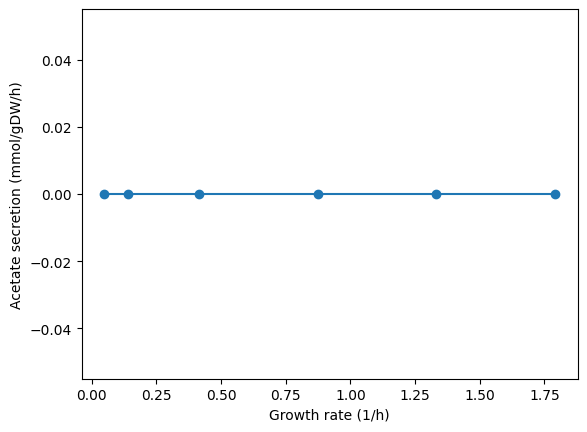

In [7]:
# make sure oxygen is available
model.reactions.EX_o2_e.lower_bound = -1000

glucose_limits = [1, 2, 5, 10, 15, 20]
growth_rates = []
acetate_rates = []

for g in glucose_limits:
    # uptake is written as a negative number, so -g means "can take up to g"
    model.reactions.EX_glc__D_e.lower_bound = -g
    solution = model.optimize()
    growth_rates.append(solution.objective_value)
    acetate_rates.append(solution.fluxes["EX_ac_e"])
    print("glucose:", g, " growth:", solution.objective_value, "acetate:", solution.fluxes["EX_ac_e"] )

plt.plot(growth_rates, acetate_rates, "o-")
plt.xlabel("Growth rate (1/h)")
plt.ylabel("Acetate secretion (mmol/gDW/h)")
plt.show()

# put glucose back to the original value
model.reactions.EX_glc__D_e.lower_bound = -10

Acetate secretion is zero at every growth rate, even at 1.79 per hour. So basic FBA does not agree with real cells here. In the model enzymes cost nothing, so respiration always wins because it gets the most ATP out of each glucose.

## Part C: adding a protein budget

A real cell has a limited amount of protein, and it must be shared between ribosomes and enzymes. Respiration gives more ATP per glucose than fermentation, but it needs more protein per ATP. Faster growth also needs more ribosomes. So at fast growth the cell needs more energy but has less protein left to make it.

I add one extra rule to the model:

`cost_resp × (respiration flux) + cost_growth × (growth rate) ≤ 1`

The respiration flux is the flux of the reaction CYTBD, the last step of the respiratory chain. Fermentation has no cost here, which is a simplification.

The two cost values are chosen by hand so that the budget becomes tight near the growth rate where real cells start to secrete acetate. So the position of the switch is an input of the model and not a prediction.

### C1. Glucose scan with the protein budget

In [8]:
cost_resp = 0.01     # protein needed per unit of respiration
cost_growth = 0.8    # protein needed per unit of growth (ribosomes)

glucose_limits = [2, 4, 6, 8, 9, 10, 11]

with model:   # everything inside is temporary and is undone afterwards
    # the new rule: respiration cost + growth cost must fit in the budget
    budget = model.problem.Constraint(
        cost_resp * model.reactions.CYTBD.flux_expression
        + cost_growth * model.reactions.Biomass_Ecoli_core.flux_expression,
        ub=1.0, name="protein_budget")
    model.add_cons_vars(budget)

    for g in glucose_limits:
        model.reactions.EX_glc__D_e.lower_bound = -g
        solution = model.optimize()
        print("glucose:", g,
              " growth:", round(solution.objective_value, 3),
              " acetate:", round(solution.fluxes["EX_ac_e"], 2),
              " oxygen:", round(-solution.fluxes["EX_o2_e"], 2))

glucose: 2  growth: 0.141  acetate: 0.0  oxygen: 5.85
glucose: 4  growth: 0.324  acetate: 0.0  oxygen: 9.84
glucose: 6  growth: 0.507  acetate: 0.0  oxygen: 13.83
glucose: 8  growth: 0.691  acetate: 0.0  oxygen: 17.81
glucose: 9  growth: 0.769  acetate: 0.57  oxygen: 19.23
glucose: 10  growth: 0.793  acetate: 3.53  oxygen: 18.28
glucose: 11  growth: 0.817  acetate: 6.48  oxygen: 17.32


Up to 8 glucose nothing changes compared to basic FBA, because the budget is not full yet. Acetate appears at a growth rate of about 0.77. After this point the growth rate still increases with more glucose, but more slowly than before, because part of the glucose is now lost as acetate. The oxygen uptake goes down after acetate appears: the cell moves protein away from respiration to make room for more ribosomes, and gets the missing energy from fermentation.

### C2. Basic FBA compared with the protein budget model

The same scan with smaller glucose steps, once without the budget and once with it.

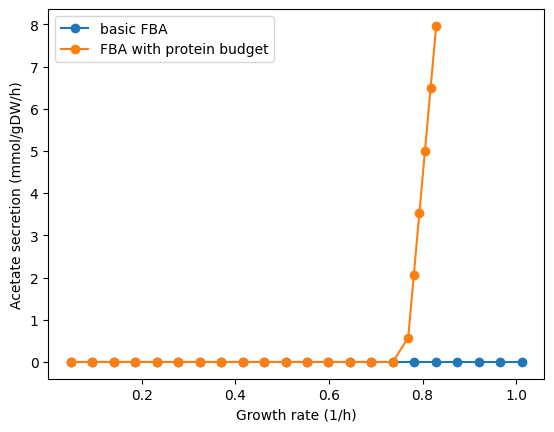

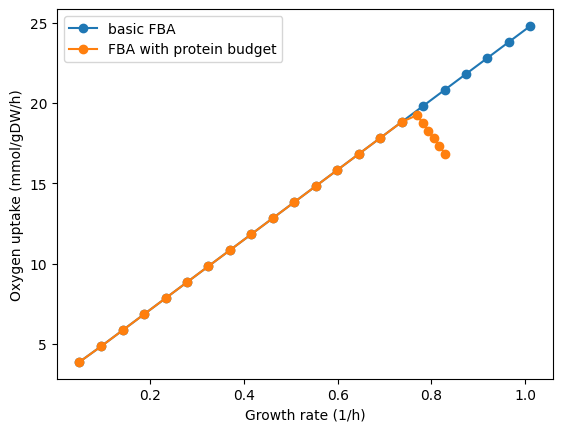

In [9]:
cost_resp = 0.01
cost_growth = 0.8
glucose_limits = np.arange(1, 12, 0.5)   # 1, 1.5, 2, ... up to 11.5

# 1) without the protein budget
growth_plain = []
acetate_plain = []
oxygen_plain = []

with model:
    for g in glucose_limits:
        model.reactions.EX_glc__D_e.lower_bound = -g
        solution = model.optimize()
        growth_plain.append(solution.objective_value)
        acetate_plain.append(solution.fluxes["EX_ac_e"])
        oxygen_plain.append(-solution.fluxes["EX_o2_e"])

# 2) with the protein budget
growth_budget = []
acetate_budget = []
oxygen_budget = []

with model:
    budget = model.problem.Constraint(
        cost_resp * model.reactions.CYTBD.flux_expression
        + cost_growth * model.reactions.Biomass_Ecoli_core.flux_expression,
        ub=1.0, name="protein_budget")
    model.add_cons_vars(budget)
    for g in glucose_limits:
        model.reactions.EX_glc__D_e.lower_bound = -g
        solution = model.optimize()
        growth_budget.append(solution.objective_value)
        acetate_budget.append(solution.fluxes["EX_ac_e"])
        oxygen_budget.append(-solution.fluxes["EX_o2_e"])

plt.plot(growth_plain, acetate_plain, "o-", label="basic FBA")
plt.plot(growth_budget, acetate_budget, "o-", label="FBA with protein budget")
plt.xlabel("Growth rate (1/h)")
plt.ylabel("Acetate secretion (mmol/gDW/h)")
plt.legend()
plt.show()

plt.plot(growth_plain, oxygen_plain, "o-", label="basic FBA")
plt.plot(growth_budget, oxygen_budget, "o-", label="FBA with protein budget")
plt.xlabel("Growth rate (1/h)")
plt.ylabel("Oxygen uptake (mmol/gDW/h)")
plt.legend()
plt.show()

In basic FBA acetate stays at zero and oxygen uptake keeps increasing with growth. With the protein budget the two models are the same at slow growth. At a growth rate of about 0.77 they separate: acetate secretion starts and increases with growth rate, and oxygen uptake starts to decrease at the same point.

Only the position of the switch was put in by hand. The increase of acetate and the decrease of respiration after the switch come out of the model, and both are also seen in experiments (Basan et al. 2015).

### C3. Does the result depend on the chosen cost?

The cost of respiration was chosen and not measured, so I repeat the scan with different values.

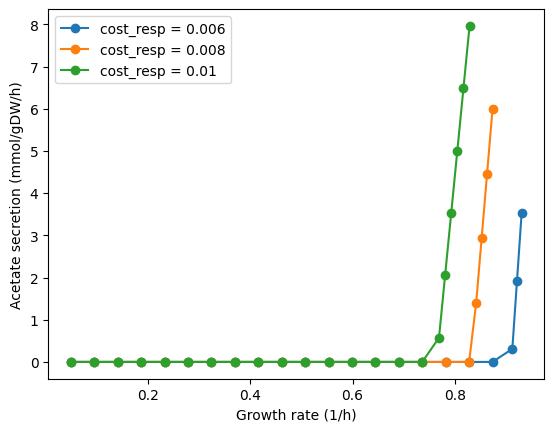

In [10]:
cost_growth = 0.8
glucose_limits = np.arange(1, 12, 0.5)
cost_list = [0.006, 0.008, 0.010]

for cost_resp in cost_list:
    growth_list = []
    acetate_list = []
    with model:
        budget = model.problem.Constraint(
            cost_resp * model.reactions.CYTBD.flux_expression
            + cost_growth * model.reactions.Biomass_Ecoli_core.flux_expression,
            ub=1.0, name="protein_budget")
        model.add_cons_vars(budget)
        for g in glucose_limits:
            model.reactions.EX_glc__D_e.lower_bound = -g
            solution = model.optimize()
            growth_list.append(solution.objective_value)
            acetate_list.append(solution.fluxes["EX_ac_e"])
    # one curve per cost value
    plt.plot(growth_list, acetate_list, "o-", label="cost_resp = " + str(cost_resp))

plt.xlabel("Growth rate (1/h)")
plt.ylabel("Acetate secretion (mmol/gDW/h)")
plt.legend()
plt.show()

The switch to acetate appears for every cost I tested, so the overflow comes from the protein budget itself and not from one special number. When respiration is more expensive, the switch comes at a lower growth rate.

Because the position of the switch depends on the cost, and the cost was not measured, this model explains why overflow happens but it cannot say at which growth rate it starts in a real cell.

## Summary and limits

- Basic FBA on the core model gives reasonable growth rates and fermentation products, but it never predicts acetate secretion when oxygen is available.
- With one extra rule for a limited protein budget, the model shows acetate overflow at fast growth and a decrease of respiration.
- The costs in the budget are chosen by hand. A real version would need measured protein costs, also for fermentation, which is free in this model.
- The figures stop at a glucose uptake of 11.5. Above this value the solver can return different acetate values for the same growth rate (alternative optimal solutions), so the result is not unique there.
- This is a small model of central metabolism only.

## References

- Basan M, Hui S, Okano H, Zhang Z, Shen Y, Williamson JR, Hwa T. Overflow metabolism in *Escherichia coli* results from efficient proteome allocation. *Nature* 528, 99–104 (2015).
- Orth JD, Fleming RMT, Palsson BØ. Reconstruction and use of microbial metabolic networks: the core *Escherichia coli* metabolic model as an educational guide. *EcoSal Plus* (2010).
- Ebrahim A, Lerman JA, Palsson BO, Hyduke DR. COBRApy: COnstraints-Based Reconstruction and Analysis for Python. *BMC Systems Biology* 7, 74 (2013).
